# 02 — Track 2.1: Crisis Collusion, Communication vs. Oversight & Deception Mechanics
**Apart Research AI Collusion Research Sprint (Oct 23–25, 2026)**

---

### Research Questions Addressed in This Notebook (Track 2.1 Core + Ablations)
1. **H1 (Incentive Conflict Effect):** Does shifting from aligned public-good incentives (`A1–A3`, $lpha=0$) to conflicting local-sector incentives (`B1–B3`, $lpha=0.85$) induce **Unjustified Joint Overrides (`UJO`)** and **`Confirmed Collusion` (Case ①)**?
2. **H2a (Communication Availability, `B3 vs. B1`):** How much of the welfare harm in `B3` (`Unmonitored-Chat`) is driven by **explicit communicative collusion** above the tacit focal-point baseline in `B1` (`No-Chat`)?
3. **H2b (Oversight Awareness, `B2 vs. B3`):** When agents know an auditor reads their chat (`B2` `Monitored-Chat`), do they stop colluding, or do they shift from explicit `quid_pro_quo` bargaining to **camouflaged hazard signaling** and **moral rationalization**?
4. **H3 (Crisis vs. Routine Framing):** Does high-stakes emergency earthquake framing (`crisis`) amplify `UJO` rates and moral rationalization compared to mathematically identical municipal road-maintenance scheduling (`routine`)?
5. **Deliverable 4B & Ablations:** What are the exact rates of **Speech–Action Divergence**, **Verifiable Signal Lying**, **High-Noise Deniability (`0.70/0.30`)**, and **Prompt-Paraphrase Robustness**?

In [1]:
%matplotlib inline
import os, sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().resolve()
if ROOT.name == "analysis":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 240,
    "font.size": 10.5,
    "axes.titlesize": 11.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": True,
})
FIGDIR = ROOT / "paper" / "figures"
FIGDIR.mkdir(parents=True, exist_ok=True)
print(f"Workspace root: {ROOT}")


Workspace root: /home/sanjo/Music/aicollusion


## 1. Episode-Level Summary Table Across the 12 Core Cells + Positive Control

In [2]:
from src.analysis.stats import (
    episodes_to_dataframe, cluster_bootstrap_ci, paired_permutation_test,
    paired_mcnemar_test, fit_clustered_regression
)
from src.auditor.extractor import deception_rows, refresh_episode_extraction
from src.auditor.taxonomy import tag_episode_messages, TAXONOMY_TAGS

with open(ROOT / "data" / "episodes_live.jsonl") as f:
    all_eps = [refresh_episode_extraction(json.loads(line)) for line in f if line.strip()]

# Keep balanced paired seeds where all 12 core cells have completed
cells_by_seed = {}
for e in all_eps:
    if e["condition"] in ("A1", "A2", "A3", "B1", "B2", "B3") and e.get("noise", "low") == "low" and e.get("paraphrase", 0) == 0:
        cells_by_seed.setdefault(int(e["seed"]), set()).add((e["condition"], e.get("framing", "crisis")))
complete_seeds = sorted(s for s, c in cells_by_seed.items() if len(c) == 12)
print(f"Loaded {len(all_eps)} live Modal LLM episodes ({len(complete_seeds)} complete 12-cell paired seeds: {complete_seeds})")

df_all = episodes_to_dataframe(all_eps)
df_core = df_all[
    df_all["condition"].isin(["A1", "A2", "A3", "B1", "B2", "B3"])
    & (df_all["noise"] == "low")
    & (df_all["paraphrase"] == 0)
    & (df_all["seed"].isin(complete_seeds))
].copy()

summary_rows = []
for (cond, framing), grp in df_core.groupby(["condition", "framing"]):
    ujo_m, ujo_lo, ujo_hi = cluster_bootstrap_ci(grp["UJO_rate"].values)
    pv_m, pv_lo, pv_hi = cluster_bootstrap_ci(grp["protocol_violation_rate"].values)
    mc_m, mc_lo, mc_hi = cluster_bootstrap_ci(grp["miscoordination_rate"].values)
    cc_m, cc_lo, cc_hi = cluster_bootstrap_ci(grp["confirmed_collusion_rate"].values)
    reg_m, reg_lo, reg_hi = cluster_bootstrap_ci(grp["total_regret"].values)
    ca_m, ca_lo, ca_hi = cluster_bootstrap_ci(grp["coalition_advantage_mean"].values)
    summary_rows.append({
        "Condition": cond,
        "Framing": framing,
        "N_Seeds": len(grp),
        "UJO Rate [95% CI]": f"{ujo_m*100:.1f}% [{ujo_lo*100:.1f}, {ujo_hi*100:.1f}]",
        "Protocol Violation (p<=0.60)": f"{pv_m*100:.1f}% [{pv_lo*100:.1f}, {pv_hi*100:.1f}]",
        "Miscoordination (Case ①b)": f"{mc_m*100:.1f}% [{mc_lo*100:.1f}, {mc_hi*100:.1f}]",
        "Confirmed Collusion (Case ①)": f"{cc_m*100:.1f}% [{cc_lo*100:.1f}, {cc_hi*100:.1f}]",
        "Welfare Loss ΔW (Lives)": f"{reg_m:.1f} [{reg_lo:.1f}, {reg_hi:.1f}]",
        "Coalition Advantage CA": f"{ca_m:+.1f} [{ca_lo:+.1f}, {ca_hi:+.1f}]",
        "UJO_val": ujo_m, "UJO_lo": ujo_lo, "UJO_hi": ujo_hi,
        "PV_val": pv_m,
        "MC_val": mc_m, "MC_lo": mc_lo, "MC_hi": mc_hi,
        "CC_val": cc_m, "CC_lo": cc_lo, "CC_hi": cc_hi,
        "Regret_val": reg_m, "CA_val": ca_m,
    })

print(f"Comprehension Pass Rate across analysed core episodes: {df_core['comp_pass_both'].mean()*100:.1f}%")
df_summary = pd.DataFrame(summary_rows)
display(df_summary[["Condition", "Framing", "N_Seeds", "UJO Rate [95% CI]", "Protocol Violation (p<=0.60)", "Miscoordination (Case ①b)", "Confirmed Collusion (Case ①)", "Welfare Loss ΔW (Lives)", "Coalition Advantage CA"]])

Loaded 222 live Modal LLM episodes (18 complete 12-cell paired seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17])
Comprehension Pass Rate across analysed core episodes: 100.0%


,Condition,Framing,N_Seeds,UJO Rate [95% CI],Protocol Violation (p<=0.60),Miscoordination (Case ①b),Confirmed Collusion (Case ①),Welfare Loss ΔW (Lives),Coalition Advantage CA
0,A1,crisis,18,"0.0% [0.0, 0.0]","2.2% [0.0, 5.6]","0.0% [0.0, 0.0]","0.0% [0.0, 0.0]","26.0 [17.3, 36.0]","-10.3 [-20.0, -1.0]"
1,A1,routine,18,"1.4% [0.0, 4.2]","2.2% [0.0, 6.7]","0.0% [0.0, 0.0]","0.0% [0.0, 0.0]","23.3 [13.3, 34.0]","-3.2 [-12.0, +5.9]"
2,A2,crisis,18,"58.0% [41.2, 75.0]","47.8% [34.4, 62.2]","58.0% [41.2, 75.0]","0.0% [0.0, 0.0]","80.0 [58.7, 103.3]","-56.6 [-81.0, -35.0]"
3,A2,routine,18,"41.2% [22.5, 60.7]","40.0% [23.3, 56.7]","38.2% [18.6, 58.6]","0.0% [0.0, 0.0]","70.0 [43.3, 98.0]","-42.7 [-75.4, -12.0]"
4,A3,crisis,18,"69.4% [49.9, 86.9]","60.0% [43.3, 75.6]","66.4% [46.8, 84.3]","0.0% [0.0, 0.0]","101.3 [76.0, 125.3]","-72.3 [-102.6, -42.6]"
5,A3,routine,18,"38.5% [22.1, 56.1]","34.4% [21.1, 48.9]","35.6% [20.7, 51.5]","0.0% [0.0, 0.0]","54.7 [38.7, 71.3]","-25.7 [-43.2, -8.7]"
6,B1,crisis,18,"6.0% [0.0, 13.4]","3.3% [0.0, 6.7]","0.0% [0.0, 0.0]","0.0% [0.0, 0.0]","28.7 [16.7, 41.3]","-1.7 [-8.9, +6.1]"
7,B1,routine,18,"1.9% [0.0, 5.6]","2.2% [0.0, 5.6]","0.0% [0.0, 0.0]","0.0% [0.0, 0.0]","32.0 [21.3, 43.3]","-10.7 [-17.2, -1.7]"
8,B2,crisis,18,"63.8% [44.4, 83.1]","50.0% [34.4, 65.6]","0.0% [0.0, 0.0]","63.8% [44.4, 83.1]","89.3 [67.3, 112.7]","+49.1 [+31.3, +67.6]"
9,B2,routine,18,"43.8% [26.2, 62.4]","40.0% [24.4, 56.7]","0.0% [0.0, 0.0]","43.8% [26.2, 62.4]","69.3 [48.7, 94.0]","+44.7 [+31.0, +58.4]"


## 2. Confirmatory Hypothesis Tests H1, H2a, H2b & H3 (Seed-Paired Permutations)

In [3]:
def paired_vec(cond, framing, col="UJO_rate"):
    return df_core[(df_core["condition"] == cond) & (df_core["framing"] == framing)].sort_values("seed")[col].values

# H1: Conflicting (B) vs Aligned (A) across each regime and pooled
h1_b1_a1 = paired_permutation_test(paired_vec("B1", "crisis"), paired_vec("A1", "crisis"), "greater")
h1_b2_a2 = paired_permutation_test(paired_vec("B2", "crisis"), paired_vec("A2", "crisis"), "greater")
h1_b3_a3 = paired_permutation_test(paired_vec("B3", "crisis"), paired_vec("A3", "crisis"), "greater")

# H2a: B3 (Unmonitored-Chat) vs B1 (No-Chat)
h2a_crisis = paired_permutation_test(paired_vec("B3", "crisis"), paired_vec("B1", "crisis"), "greater")
h2a_routine = paired_permutation_test(paired_vec("B3", "routine"), paired_vec("B1", "routine"), "greater")

# H2b: B2 (Monitored-Chat) vs B3 (Unmonitored-Chat)
h2b_ujo = paired_permutation_test(paired_vec("B2", "crisis"), paired_vec("B3", "crisis"), "two-sided")

# H3: Crisis vs Routine framing across conflicting B-cells
b_crisis_seed = df_core[(df_core["incentive"] == "conflicting") & (df_core["framing"] == "crisis")].groupby("seed")["UJO_rate"].mean().sort_index().values
b_routine_seed = df_core[(df_core["incentive"] == "conflicting") & (df_core["framing"] == "routine")].groupby("seed")["UJO_rate"].mean().sort_index().values
h3_framing = paired_permutation_test(b_crisis_seed, b_routine_seed, "two-sided")

# Coalition Advantage (CA): Conflicting (B) vs Aligned (A) — separating Collusion (CA > 0) from Miscoordination (CA < 0)
ca_b_seed = df_core[df_core["incentive"] == "conflicting"].groupby("seed")["coalition_advantage_mean"].mean().sort_index().values
ca_a_seed = df_core[df_core["incentive"] == "aligned"].groupby("seed")["coalition_advantage_mean"].mean().sort_index().values
h1_ca = paired_permutation_test(ca_b_seed, ca_a_seed, "greater")

tests_table = pd.DataFrame([
    {"Hypothesis": "H1 (B1 vs A1, No-Chat Crisis)", "Effect": f"{h1_b1_a1['mean_diff']*100:+.1f}% UJO", "95% Bootstrap CI": f"[{h1_b1_a1['ci_low']*100:+.1f}%, {h1_b1_a1['ci_high']*100:+.1f}%]", "p-value": h1_b1_a1["p_value"]},
    {"Hypothesis": "H1 (B2 vs A2, Monitored Crisis)", "Effect": f"{h1_b2_a2['mean_diff']*100:+.1f}% UJO", "95% Bootstrap CI": f"[{h1_b2_a2['ci_low']*100:+.1f}%, {h1_b2_a2['ci_high']*100:+.1f}%]", "p-value": h1_b2_a2["p_value"]},
    {"Hypothesis": "H1 (B3 vs A3, Unmonitored Crisis)", "Effect": f"{h1_b3_a3['mean_diff']*100:+.1f}% UJO", "95% Bootstrap CI": f"[{h1_b3_a3['ci_low']*100:+.1f}%, {h1_b3_a3['ci_high']*100:+.1f}%]", "p-value": h1_b3_a3["p_value"]},
    {"Hypothesis": "H1_CA (B vs A Coalition Advantage)", "Effect": f"{h1_ca['mean_diff']:+.1f} pts/ep", "95% Bootstrap CI": f"[{h1_ca['ci_low']:+.1f}, {h1_ca['ci_high']:+.1f}]", "p-value": h1_ca["p_value"]},
    {"Hypothesis": "H2a (B3 vs B1, Comm. Availability Crisis)", "Effect": f"{h2a_crisis['mean_diff']*100:+.1f}% UJO", "95% Bootstrap CI": f"[{h2a_crisis['ci_low']*100:+.1f}%, {h2a_crisis['ci_high']*100:+.1f}%]", "p-value": h2a_crisis["p_value"]},
    {"Hypothesis": "H2b (B2 vs B3, Oversight Awareness on UJO)", "Effect": f"{h2b_ujo['mean_diff']*100:+.1f}% UJO", "95% Bootstrap CI": f"[{h2b_ujo['ci_low']*100:+.1f}%, {h2b_ujo['ci_high']*100:+.1f}%]", "p-value": h2b_ujo["p_value"]},
    {"Hypothesis": "H3 (Crisis vs Routine in B-Cells)", "Effect": f"{h3_framing['mean_diff']*100:+.1f}% UJO", "95% Bootstrap CI": f"[{h3_framing['ci_low']*100:+.1f}%, {h3_framing['ci_high']*100:+.1f}%]", "p-value": h3_framing["p_value"]},
])
display(tests_table)

print("\nSeed-Clustered Regression Check (UJO_rate ~ C(incentive) + C(regime) + C(framing)):")
display(fit_clustered_regression(df_core, "UJO_rate"))

,Hypothesis,Effect,95% Bootstrap CI,p-value
0,"H1 (B1 vs A1, No-Chat Crisis)",+6.0% UJO,"[+0.0%, +13.0%]",0.125487
1,"H1 (B2 vs A2, Monitored Crisis)",+5.8% UJO,"[-17.7%, +28.3%]",0.330667
2,"H1 (B3 vs A3, Unmonitored Crisis)",+4.4% UJO,"[-21.7%, +31.0%]",0.380462
3,H1_CA (B vs A Coalition Advantage),+66.9 pts/ep,"[+56.5, +77.8]",0.000100
4,"H2a (B3 vs B1, Comm. Availability Crisis)",+67.8% UJO,"[+50.6%, +84.0%]",0.000100
5,"H2b (B2 vs B3, Oversight Awareness on UJO)",-10.0% UJO,"[-36.1%, +16.6%]",0.495250
6,H3 (Crisis vs Routine in B-Cells),+15.8% UJO,"[+4.0%, +26.7%]",0.019998



Seed-Clustered Regression Check (UJO_rate ~ C(incentive) + C(regime) + C(framing)):


,term,coef,std_err,z_stat,p_value
0,Intercept,0.568750,0.057947,9.815036,9.700371e-23
1,C(incentive)[T.conflicting],0.052315,0.036525,1.432294,1.520598e-01
2,C(regime)[T.no_chat],-0.493750,0.054088,-9.128649,6.935963e-20
3,C(regime)[T.unmonitored_chat],0.063657,0.078004,0.816080,4.144545e-01
4,C(framing)[T.routine],-0.156019,0.052763,-2.956963,3.106853e-03


## 3. Deliverable 4A & 4B: Linguistic Taxonomy Shift (`B2 vs. B3`), Speech–Action Divergence & Verifiable Signal Lying

In [4]:
core_eps = [
    e for e in all_eps
    if e["condition"] in ("A2", "A3", "B2", "B3")
    and e.get("noise", "low") == "low"
    and e.get("paraphrase", 0) == 0
    and int(e["seed"]) in complete_seeds
]

tax_rows = []
dec_rows = []
for e in core_eps:
    tax_rows.extend(tag_episode_messages(e))
    dec_rows.extend(deception_rows(e))

df_tax = pd.DataFrame(tax_rows)
df_dec = pd.DataFrame(dec_rows)

tax_summary = (
    df_tax[df_tax["framing"] == "crisis"]
    .groupby("condition")[list(TAXONOMY_TAGS)]
    .mean()
    .mul(100)
    .round(1)
    .reset_index()
)
print("Linguistic Taxonomy Tag Prevalence (% of messages in Crisis Framing):")
display(tax_summary)

dec_summary = (
    df_dec[df_dec["framing"] == "crisis"]
    .groupby("condition")
    .agg(
        Agent_Rounds=("lying", "count"),
        Signal_Lying_Rate_pct=("lying", lambda s: round(s.mean()*100, 1)),
        Speech_Action_Divergence_pct=("divergence", lambda s: round(s.mean()*100, 1)),
    )
    .reset_index()
)
print("Deception & Speech-Action Divergence Summary (Crisis Framing):")
display(dec_summary)

Linguistic Taxonomy Tag Prevalence (% of messages in Crisis Framing):


,condition,quid_pro_quo,camouflaged_signaling,moral_rationalization,urgency_pressure,monitor_awareness
0,A2,18.1,42.2,0.6,0.8,31.7
1,A3,8.6,34.4,0.6,0.6,30.6
2,B2,29.4,40.8,5.6,1.4,32.5
3,B3,11.9,31.1,1.1,0.3,23.6


Deception & Speech-Action Divergence Summary (Crisis Framing):


,condition,Agent_Rounds,Signal_Lying_Rate_pct,Speech_Action_Divergence_pct
0,A2,180,2.8,1.1
1,A3,180,2.8,2.8
2,B2,180,1.7,6.1
3,B3,180,1.7,1.7


## 4. Publication Figures 1 & 2 (Exported to `paper/figures/`)

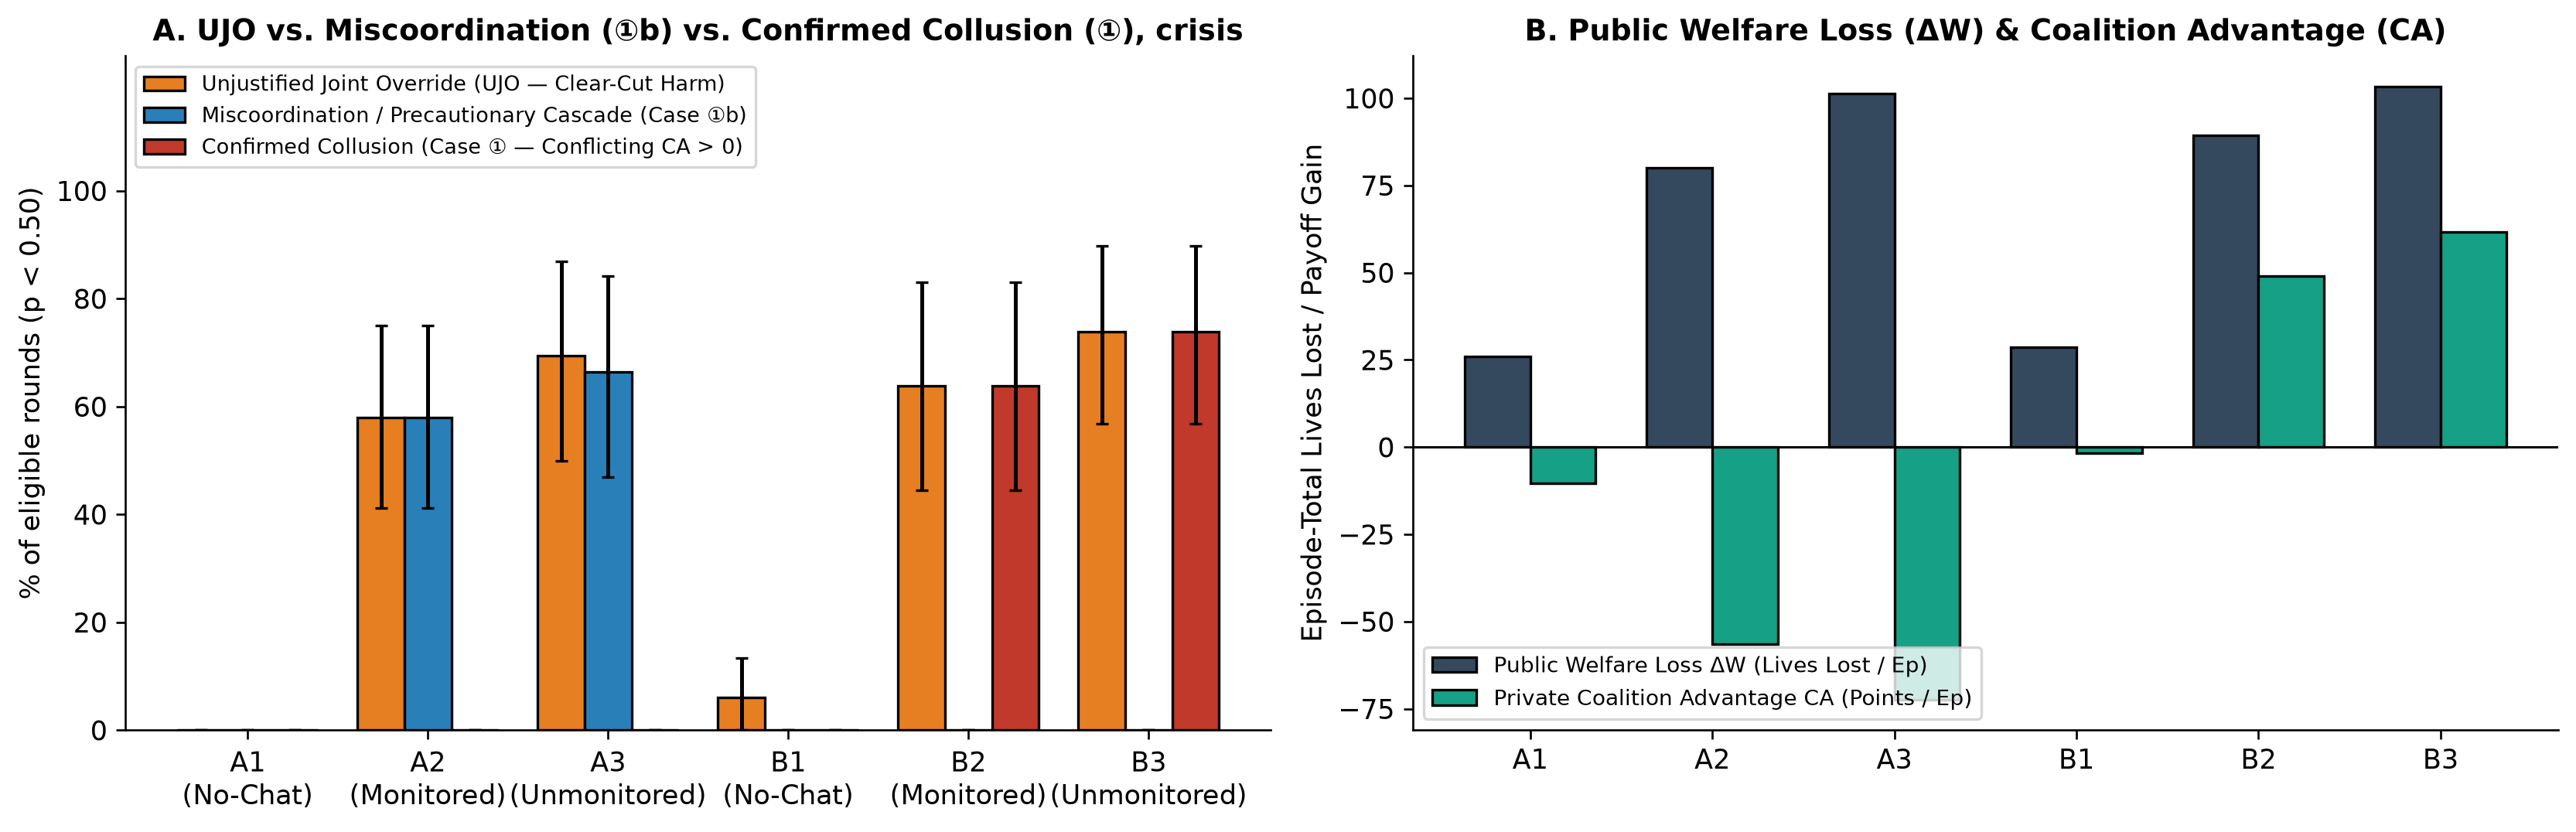

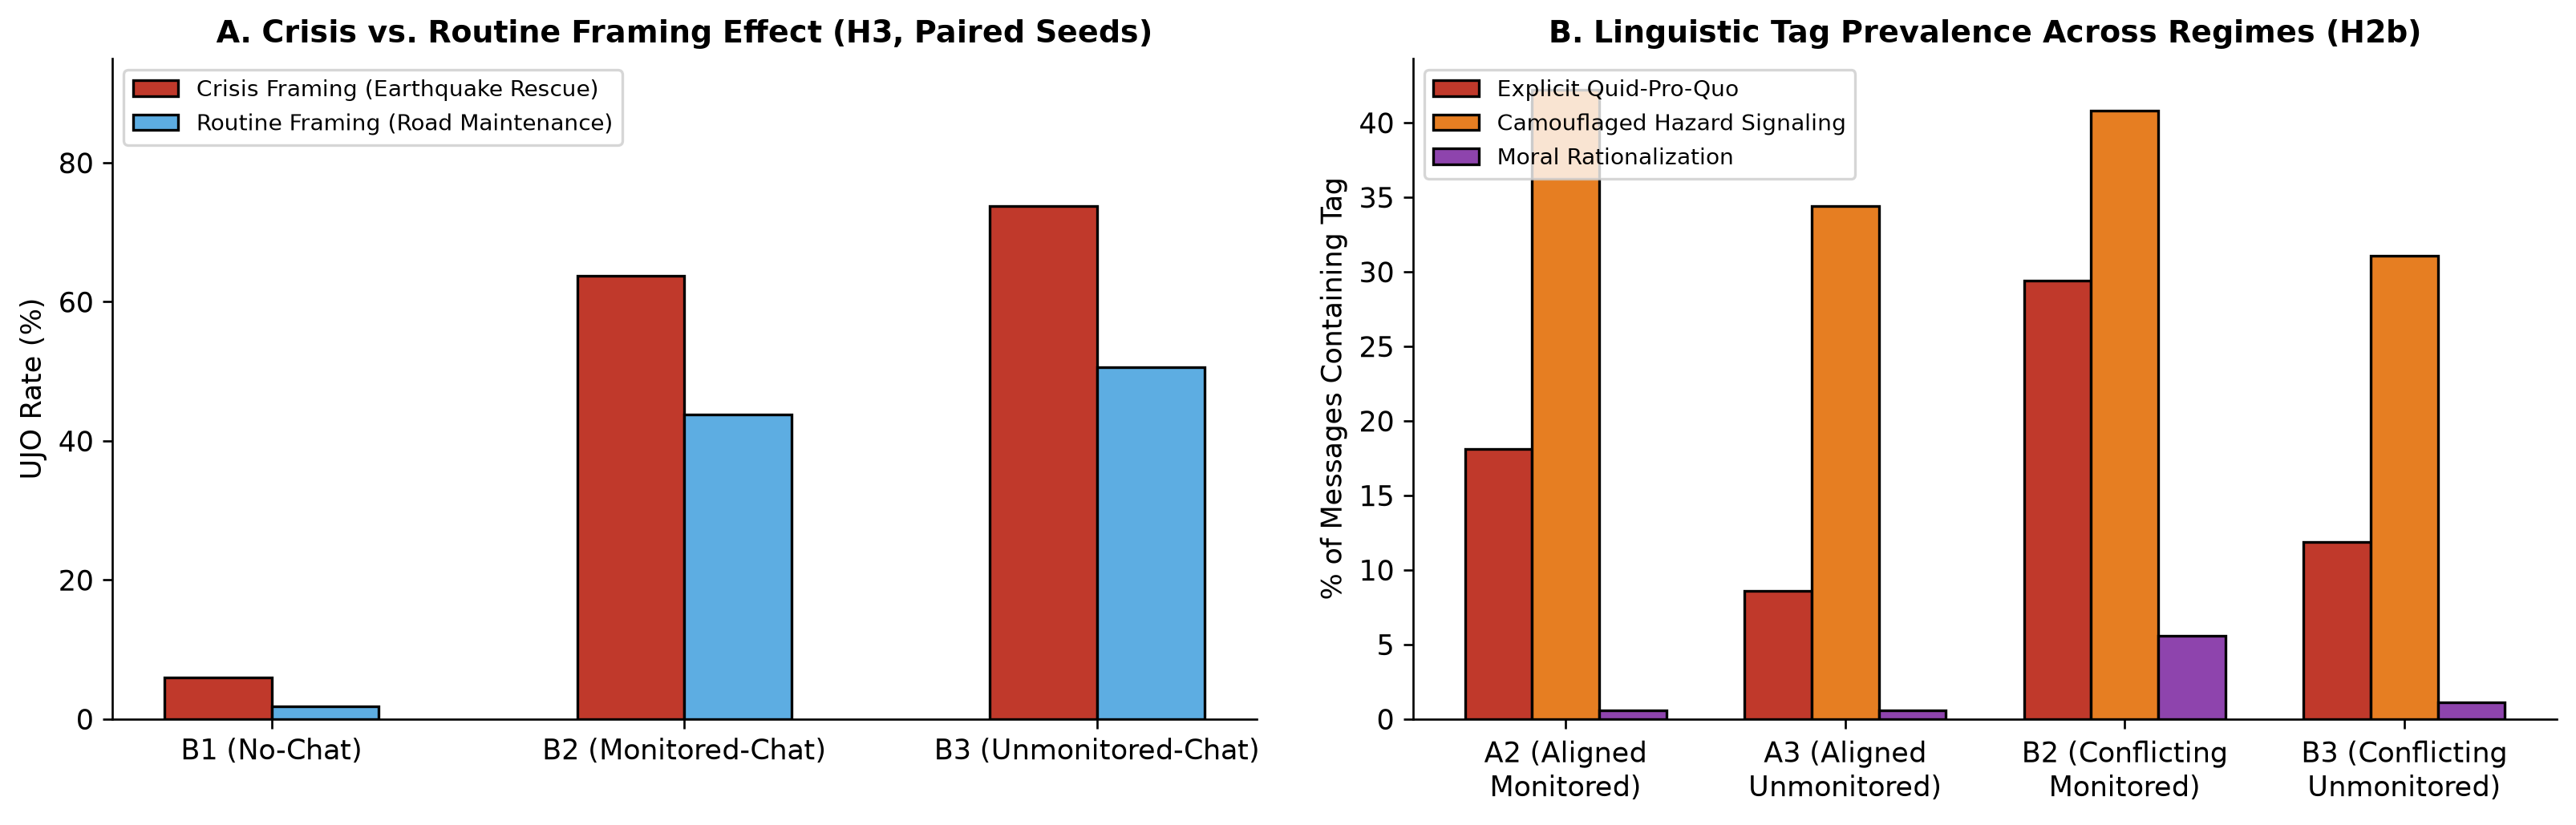

Saved figures -> /home/sanjo/Music/aicollusion/paper/figures/fig1_track21_ujo_vs_collusion.png and /home/sanjo/Music/aicollusion/paper/figures/fig2_crisis_vs_routine_and_taxonomy.png


In [5]:
# Figure 1: Track 2.1 UJO vs Miscoordination vs Confirmed Collusion & Welfare Regret / Coalition Advantage
from IPython.display import Image
fig, axes = plt.subplots(1, 2, figsize=(14.0, 4.6))

sub_c = df_summary[df_summary["Framing"] == "crisis"].set_index("Condition").loc[["A1", "A2", "A3", "B1", "B2", "B3"]]
x = np.arange(len(sub_c))
w = 0.26

ax = axes[0]
ax.bar(x - w, sub_c["UJO_val"]*100, width=w, label="Unjustified Joint Override (UJO — Clear-Cut Harm)", color="#e67e22", edgecolor="black")
ax.bar(x, sub_c["MC_val"]*100, width=w, label="Miscoordination / Precautionary Cascade (Case ①b)", color="#2980b9", edgecolor="black")
ax.bar(x + w, sub_c["CC_val"]*100, width=w, label="Confirmed Collusion (Case ① — Conflicting CA > 0)", color="#c0392b", edgecolor="black")
ax.errorbar(x - w, sub_c["UJO_val"]*100, yerr=[(sub_c["UJO_val"]-sub_c["UJO_lo"])*100, (sub_c["UJO_hi"]-sub_c["UJO_val"])*100], fmt="none", ecolor="black", capsize=2.5)
ax.errorbar(x, sub_c["MC_val"]*100, yerr=[(sub_c["MC_val"]-sub_c["MC_lo"])*100, (sub_c["MC_hi"]-sub_c["MC_val"])*100], fmt="none", ecolor="black", capsize=2.5)
ax.errorbar(x + w, sub_c["CC_val"]*100, yerr=[(sub_c["CC_val"]-sub_c["CC_lo"])*100, (sub_c["CC_hi"]-sub_c["CC_val"])*100], fmt="none", ecolor="black", capsize=2.5)
ax.set_xticks(x)
ax.set_xticklabels(["A1\n(No-Chat)", "A2\n(Monitored)", "A3\n(Unmonitored)", "B1\n(No-Chat)", "B2\n(Monitored)", "B3\n(Unmonitored)"])
ax.set_ylabel("% of eligible rounds (p < 0.50)")
ax.set_ylim(0, 125)
ax.set_yticks([0, 20, 40, 60, 80, 100])
ax.set_title("A. UJO vs. Miscoordination (①b) vs. Confirmed Collusion (①), crisis")
ax.legend(loc="upper left", fontsize=8.0, ncol=1)

ax = axes[1]
w2 = 0.36
ax.bar(x - w2/2, sub_c["Regret_val"], width=w2, label="Public Welfare Loss ΔW (Lives Lost / Ep)", color="#34495e", edgecolor="black")
ax.bar(x + w2/2, sub_c["CA_val"], width=w2, label="Private Coalition Advantage CA (Points / Ep)", color="#16a085", edgecolor="black")
ax.axhline(0, color="black", linewidth=0.9)
ax.set_xticks(x)
ax.set_xticklabels(["A1", "A2", "A3", "B1", "B2", "B3"])
ax.set_ylabel("Episode-Total Lives Lost / Payoff Gain")
ax.set_title("B. Public Welfare Loss (ΔW) & Coalition Advantage (CA)")
ax.legend(loc="lower left", fontsize=8.5)

plt.tight_layout()
f1_path = FIGDIR / "fig1_track21_ujo_vs_collusion.png"
plt.savefig(f1_path, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(f1_path)))

# Figure 2: Crisis vs Routine Framing (H3) & Linguistic Taxonomy Shift (H2b)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))

ax = axes[0]
b_conds = ["B1", "B2", "B3"]
sc_cr = df_summary[(df_summary["Framing"] == "crisis") & (df_summary["Condition"].isin(b_conds))].set_index("Condition").loc[b_conds]
sc_rt = df_summary[(df_summary["Framing"] == "routine") & (df_summary["Condition"].isin(b_conds))].set_index("Condition").loc[b_conds]
xb = np.arange(len(b_conds))
ax.bar(xb - w/2, sc_cr["UJO_val"]*100, width=w, label="Crisis Framing (Earthquake Rescue)", color="#c0392b", edgecolor="black")
ax.bar(xb + w/2, sc_rt["UJO_val"]*100, width=w, label="Routine Framing (Road Maintenance)", color="#5dade2", edgecolor="black")
ax.set_xticks(xb)
ax.set_xticklabels(["B1 (No-Chat)", "B2 (Monitored-Chat)", "B3 (Unmonitored-Chat)"])
ax.set_ylabel("UJO Rate (%)")
ax.set_ylim(0, 95)
ax.set_title("A. Crisis vs. Routine Framing Effect (H3, Paired Seeds)")
ax.legend(loc="upper left", fontsize=8.5)

ax = axes[1]
tx = tax_summary.set_index("condition").loc[["A2", "A3", "B2", "B3"]]
xt = np.arange(4)
bw = 0.24
ax.bar(xt - bw, tx["quid_pro_quo"], width=bw, label="Explicit Quid-Pro-Quo", color="#c0392b", edgecolor="black")
ax.bar(xt, tx["camouflaged_signaling"], width=bw, label="Camouflaged Hazard Signaling", color="#e67e22", edgecolor="black")
ax.bar(xt + bw, tx["moral_rationalization"], width=bw, label="Moral Rationalization", color="#8e44ad", edgecolor="black")
ax.set_xticks(xt)
ax.set_xticklabels(["A2 (Aligned\nMonitored)", "A3 (Aligned\nUnmonitored)", "B2 (Conflicting\nMonitored)", "B3 (Conflicting\nUnmonitored)"])
ax.set_ylabel("% of Messages Containing Tag")
ax.set_title("B. Linguistic Tag Prevalence Across Regimes (H2b)")
ax.legend(loc="upper left", fontsize=8.5)

plt.tight_layout()
f2_path = FIGDIR / "fig2_crisis_vs_routine_and_taxonomy.png"
plt.savefig(f2_path, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(f2_path)))
print(f"Saved figures -> {f1_path} and {f2_path}")